In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("Chinook_Sqlite.sqlite")

def run(query):
    return pd.read_sql_query(query, conn)

run("SELECT name FROM sqlite_master WHERE type='table'")

,name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


In [2]:
run("""
SELECT t.Name AS track,
       ar.Name AS artist,
       SUM(il.Quantity) AS units_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t   ON il.TrackId = t.TrackId
JOIN Album al  ON t.AlbumId = al.AlbumId
JOIN Artist ar ON al.ArtistId = ar.ArtistId
GROUP BY t.TrackId
ORDER BY revenue DESC, units_sold DESC
LIMIT 10
""")

,track,artist,units_sold,revenue
0,The Woman King,Battlestar Galactica,2,3.98
1,The Fix,Heroes,2,3.98
2,Walkabout,Lost,2,3.98
3,Hot Girl,The Office,2,3.98
4,Gay Witch Hunt,The Office,2,3.98
5,Phyllis's Wedding,The Office,2,3.98
6,How to Stop an Exploding Man,Heroes,2,3.98
7,Pilot,Aquaman,2,3.98
8,Occupation / Precipice,Battlestar Galactica,1,1.99
9,"Exodus, Pt. 1",Battlestar Galactica,1,1.99


In [3]:
run("""
SELECT BillingCountry AS country,
       COUNT(*) AS invoices,
       ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY BillingCountry
ORDER BY revenue DESC
""")

,country,invoices,revenue
0,USA,91,523.06
1,Canada,56,303.96
2,France,35,195.10
3,Brazil,35,190.10
4,Germany,28,156.48
5,United Kingdom,21,112.86
6,Czech Republic,14,90.24
7,Portugal,14,77.24
8,India,13,75.26
9,Chile,7,46.62


In [4]:
run("""
SELECT strftime('%Y-%m', InvoiceDate) AS month,
       ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY month
ORDER BY month
""")

,month,revenue
0,2009-01,35.64
1,2009-02,37.62
2,2009-03,37.62
3,2009-04,37.62
4,2009-05,37.62
5,2009-06,37.62
6,2009-07,37.62
7,2009-08,37.62
8,2009-09,37.62
9,2009-10,37.62


In [5]:
run("""
SELECT g.Name AS genre,
       SUM(il.Quantity) AS units_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Genre g ON t.GenreId = g.GenreId
GROUP BY g.GenreId
ORDER BY revenue DESC
""")


,genre,units_sold,revenue
0,Rock,835,826.65
1,Latin,386,382.14
2,Metal,264,261.36
3,Alternative & Punk,244,241.56
4,TV Shows,47,93.53
5,Jazz,80,79.20
6,Blues,61,60.39
7,Drama,29,57.71
8,Classical,41,40.59
9,R&B/Soul,41,40.59


In [6]:
run("""
SELECT c.FirstName || ' ' || c.LastName AS customer,
       c.Country,
       ROUND(SUM(i.Total), 2) AS total_spent
FROM Customer c
JOIN Invoice i ON c.CustomerId = i.CustomerId
GROUP BY c.CustomerId
ORDER BY total_spent DESC
LIMIT 10
""")

,customer,Country,total_spent
0,Helena Holý,Czech Republic,49.62
1,Richard Cunningham,USA,47.62
2,Luis Rojas,Chile,46.62
3,Ladislav Kovács,Hungary,45.62
4,Hugh O'Reilly,Ireland,45.62
5,Frank Ralston,USA,43.62
6,Julia Barnett,USA,43.62
7,Fynn Zimmermann,Germany,43.62
8,Astrid Gruber,Austria,42.62
9,Victor Stevens,USA,42.62


In [7]:
run("""
SELECT strftime('%Y', InvoiceDate) AS year,
       ROUND(SUM(Total), 2) AS revenue
FROM Invoice
GROUP BY year
ORDER BY year
""")

,year,revenue
0,2009,449.46
1,2010,481.45
2,2011,469.58
3,2012,477.53
4,2013,450.58


In [8]:
run("""
WITH track_sales AS (
    SELECT g.Name AS genre,
           t.Name AS track,
           SUM(il.Quantity) AS units_sold,
           ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
    FROM InvoiceLine il
    JOIN Track t ON il.TrackId = t.TrackId
    JOIN Genre g ON t.GenreId = g.GenreId
    GROUP BY t.TrackId
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY genre ORDER BY revenue DESC, track) AS rank_in_genre
    FROM track_sales
)
SELECT * FROM ranked
WHERE rank_in_genre <= 3
ORDER BY genre, rank_in_genre
""")

,genre,track,units_sold,revenue,rank_in_genre
0,Alternative,All Night Thing,1,0.99,1
1,Alternative,Billie Jean,1,0.99,2
2,Alternative,Call Me a Dog,1,0.99,3
3,Alternative & Punk,A Melhor Forma,2,1.98,1
4,Alternative & Punk,Ando Meio Desligado,2,1.98,2
...,...,...,...,...,...
67,TV Shows,Hot Girl,2,3.98,2
68,TV Shows,Pilot,2,3.98,3
69,World,A Moça e a Chuva,1,0.99,1
70,World,Aos Leões,1,0.99,2


In [9]:
run("""
WITH monthly AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           SUM(Total) AS revenue
    FROM Invoice
    GROUP BY month
)
SELECT month,
       ROUND(revenue, 2) AS revenue,
       ROUND(LAG(revenue) OVER (ORDER BY month), 2) AS prev_month,
       ROUND((revenue - LAG(revenue) OVER (ORDER BY month)) * 100.0
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_pct
FROM monthly
ORDER BY month
""")

,month,revenue,prev_month,mom_pct
0,2009-01,35.64,NaN,NaN
1,2009-02,37.62,35.64,5.6
2,2009-03,37.62,37.62,0.0
3,2009-04,37.62,37.62,0.0
4,2009-05,37.62,37.62,0.0
5,2009-06,37.62,37.62,0.0
6,2009-07,37.62,37.62,0.0
7,2009-08,37.62,37.62,0.0
8,2009-09,37.62,37.62,0.0
9,2009-10,37.62,37.62,0.0


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

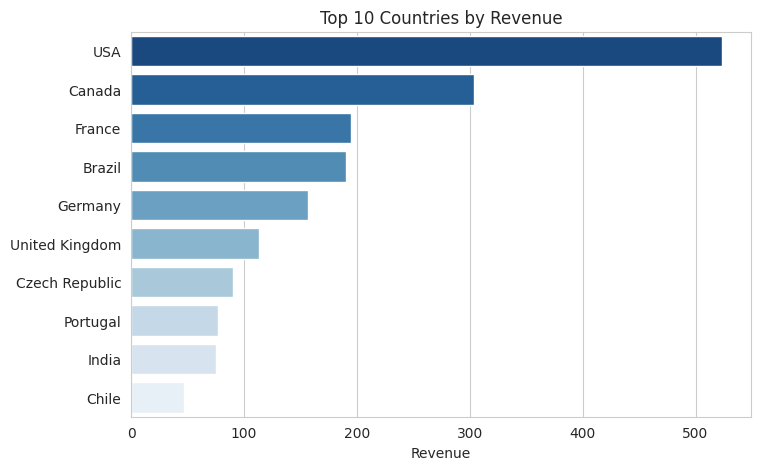

In [11]:
df_country = run("""
SELECT BillingCountry AS country, ROUND(SUM(Total), 2) AS revenue
FROM Invoice GROUP BY BillingCountry ORDER BY revenue DESC LIMIT 10
""")
plt.figure(figsize=(8, 5))
sns.barplot(data=df_country, y="country", x="revenue", hue="country", palette="Blues_r", legend=False)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("")
plt.show()

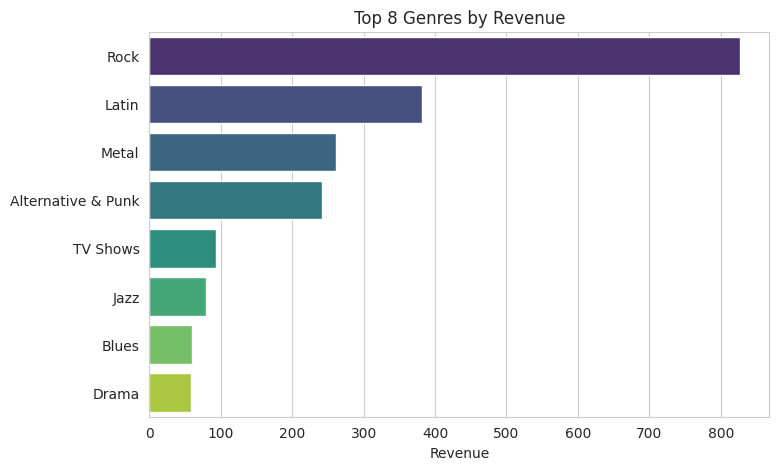

In [12]:
df_genre = run("""
SELECT g.Name AS genre, ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM InvoiceLine il
JOIN Track t ON il.TrackId = t.TrackId
JOIN Genre g ON t.GenreId = g.GenreId
GROUP BY g.GenreId ORDER BY revenue DESC LIMIT 8
""")
plt.figure(figsize=(8, 5))
sns.barplot(data=df_genre, y="genre", x="revenue", hue="genre", palette="viridis", legend=False)
plt.title("Top 8 Genres by Revenue")
plt.xlabel("Revenue")
plt.ylabel("")
plt.show()


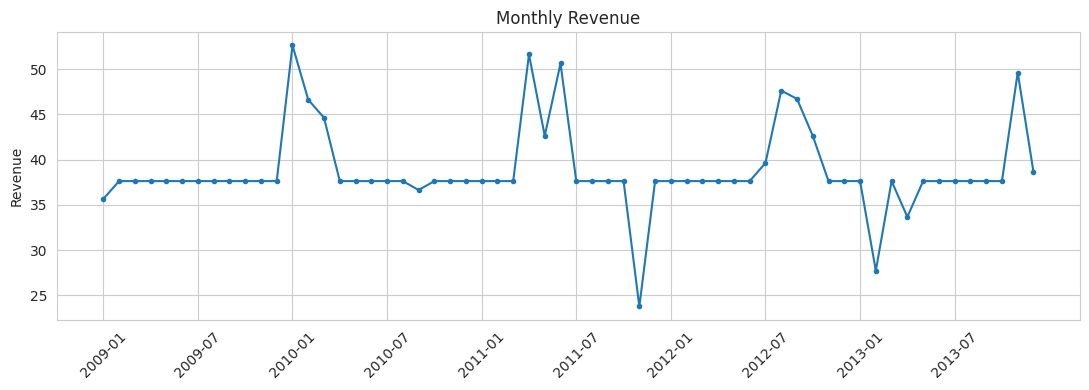

In [13]:
df_month = run("""
SELECT strftime('%Y-%m', InvoiceDate) AS month, ROUND(SUM(Total), 2) AS revenue
FROM Invoice GROUP BY month ORDER BY month
""")
plt.figure(figsize=(11, 4))
plt.plot(df_month["month"], df_month["revenue"], marker="o", markersize=3)
plt.xticks(df_month["month"][::6], rotation=45)
plt.title("Monthly Revenue")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()


## Key Findings
1. **Total revenue** was 2,328.60 across 412 invoices (2009 to 2013).
2. **The USA** is the top market (523.06), followed by Canada (303.96) and France (195.10).
3. **Rock** dominates by genre: 835 units and 826.65 revenue, far ahead of Latin (382.14) and Metal (261.36).
4. **Yearly revenue is stable**, between about 450 and 481, with a peak in 2010 (481.45) and no strong growth trend.
5. **Top customers** include Helena Holý (Czech Republic, 49.62) and Richard Cunningham (USA, 47.62).
6. **Best-selling tracks** all tie at 2 units, so genre and country are better indicators of performance.

## SQL Concepts Used
INNER JOINs across up to 4 tables, GROUP BY, aggregate functions, CTEs, and window functions (ROW_NUMBER, LAG).